# Modul 4 — Statistik Keandalan (Reliability)
Pertanyaan teknik: *seberapa sering tiap unit gagal, seberapa lama diperbaiki, apakah kegagalan makin sering, dan kapan komponen sebaiknya diganti?*

Isi: (A) MTBF/MTTR/availability per unit dari `Downtime_Log`, (B) uji tren Laplace + model Crow-AMSAA, (C) Weibull dengan data tersensor & left-truncated dari `Komponen_Kritis`, (D) umur B10 dan interval penggantian.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

pd.set_option("display.width", 140, "display.max_columns", 30)
XLSX = "Smelter_Data_Lanjutan.xlsx"
try:
    from google.colab import files
    if not os.path.exists(XLSX): files.upload()
except ImportError:
    pass
S = pd.read_excel(XLSX, sheet_name=None)
log, harian, komp = S["Downtime_Log"], S["Data_Harian"], S["Komponen_Kritis"]
log["Tanggal"] = pd.to_datetime(log.Tanggal); harian["Tanggal"] = pd.to_datetime(harian.Tanggal)
rng = np.random.default_rng(7)
T0 = harian.Tanggal.min(); HARI = len(harian); JAM = HARI * 24
tak = log[log.Kategori == "Tidak Terjadwal"].copy()
tak["t_hari"] = (tak.Tanggal - T0).dt.days + 0.5            # waktu kejadian (hari sejak 1 Jan)
print(f"Jendela: {HARI} hari = {JAM} jam | kejadian tidak terjadwal: {len(tak)}")

Saving Smelter_Data_Lanjutan.xlsx to Smelter_Data_Lanjutan.xlsx
Jendela: 273 hari = 6552 jam | kejadian tidak terjadwal: 58


## A. MTBF, MTTR, dan availability inheren per unit
- **MTTR** = rata-rata durasi perbaikan.
- **MTBF** = jam operasi ÷ jumlah kegagalan, dengan jam operasi unit ≈ jendela − downtime unit itu.
- **Availability inheren** = MTBF / (MTBF + MTTR).

In [ ]:
u = tak.groupby("Unit").agg(Kejadian=("Durasi_Jam", "size"), Jam_Down=("Durasi_Jam", "sum"), MTTR_jam=("Durasi_Jam", "mean"))
u["Jam_Operasi"] = JAM - u.Jam_Down
u["MTBF_jam"] = u.Jam_Operasi / u.Kejadian
u["Avail_inheren_%"] = u.MTBF_jam / (u.MTBF_jam + u.MTTR_jam) * 100
print(u.sort_values("Jam_Down", ascending=False).round(1))
n, dt = len(tak), tak.Durasi_Jam.sum()
print(f"\nPABRIK: MTBF={(JAM-dt)/n:.1f} jam (≈{(JAM-dt)/n/24:.1f} hari), MTTR={dt/n:.2f} jam")

                               Kejadian  Jam_Down  MTTR_jam  Jam_Operasi  MTBF_jam  Avail_inheren_%
Unit                                                                                               
Oxygen Plant                         11      40.5       3.7       6511.5     592.0             99.4
Flash Smelting Furnace               11      27.5       2.5       6524.5     593.1             99.6
Converter                             8      26.0       3.2       6526.0     815.8             99.6
Acid Plant                            8      25.0       3.1       6527.0     815.9             99.6
Refinery (Tankhouse)                  6      20.5       3.4       6531.5    1088.6             99.7
Pembangkit/Listrik                    6      17.5       2.9       6534.5    1089.1             99.7
Anode Furnace                         3      12.0       4.0       6540.0    2180.0             99.8
Material Handling & Pelabuhan         5       8.5       1.7       6543.5    1308.7             99.9


## B. Apakah kegagalan makin sering? — uji Laplace & Crow-AMSAA
Uji Laplace: jika kejadian cenderung bergeser ke akhir jendela, statistik **U > 0** (memburuk); **U < 0** membaik; |U| > 1,96 berarti signifikan pada 5%.

Seluruh pabrik: U=0.70, p=0.484 -> tidak ada tren signifikan
Per unit (n kecil, hati-hati):
  Acid Plant                     n= 8  U=-0.15  p=0.879
  Converter                      n= 8  U=-1.79  p=0.073
  Flash Smelting Furnace         n=11  U=-0.09  p=0.930
  Material Handling & Pelabuhan  n= 5  U=+1.16  p=0.245
  Oxygen Plant                   n=11  U=+0.94  p=0.345
  Pembangkit/Listrik             n= 6  U=+1.35  p=0.178
  Refinery (Tankhouse)           n= 6  U=+0.62  p=0.538

Crow-AMSAA: beta=1.10 (CI95% ≈ [0.84, 1.40]), lambda=0.1208


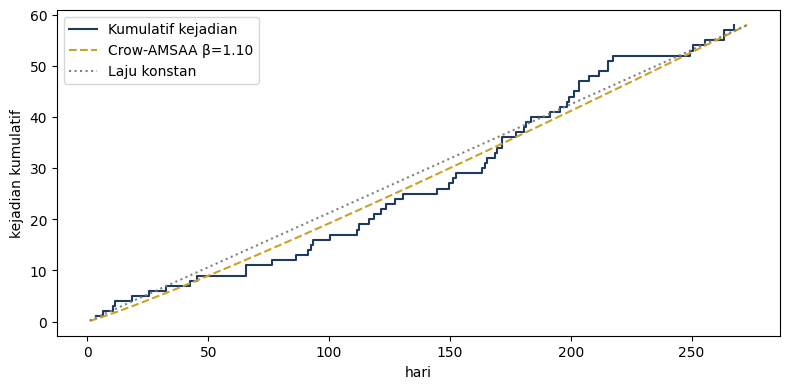

In [ ]:
def laplace(t, T):
    t = np.asarray(t, float); n = len(t); U = (t.mean() - T/2) / (T / np.sqrt(12*n)); return U, 2*stats.norm.sf(abs(U))
U, p = laplace(tak.t_hari, HARI)
print(f"Seluruh pabrik: U={U:.2f}, p={p:.3f} -> {'ada tren' if p<.05 else 'tidak ada tren signifikan'}")
print("Per unit (n kecil, hati-hati):")
for unit, g in tak.groupby("Unit"):
    if len(g) >= 4: Uu, pu = laplace(g.t_hari, HARI); print(f"  {unit:30s} n={len(g):2d}  U={Uu:+.2f}  p={pu:.3f}")

# Crow-AMSAA (NHPP hukum pangkat): N(t)=lambda * t^beta. beta<1 membaik, >1 memburuk. MLE untuk data dipotong waktu:
t = np.sort(tak.t_hari.values); beta = len(t) / np.log(HARI / t).sum(); lam = len(t) / HARI**beta
# CI beta: 2*n*beta_true/beta_hat ~ chi2(2n)  (kira-kira)
lo, hi = beta * stats.chi2.ppf([.025, .975], 2*len(t)) / (2*len(t))
print(f"\nCrow-AMSAA: beta={beta:.2f} (CI95% ≈ [{lo:.2f}, {hi:.2f}]), lambda={lam:.4f}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.step(t, np.arange(1, len(t)+1), where="post", color="#1F3A5F", label="Kumulatif kejadian")
g_ = np.linspace(1, HARI, 200); ax.plot(g_, lam * g_**beta, "--", color="#C9A227", label=f"Crow-AMSAA β={beta:.2f}")
ax.plot(g_, len(t)*g_/HARI, ":", color="gray", label="Laju konstan"); ax.set_xlabel("hari"); ax.set_ylabel("kejadian kumulatif"); ax.legend()
plt.tight_layout(); plt.show()

## C. Weibull dengan sensor & left truncation
Data `Komponen_Kritis`: tiap komponen punya `Umur_Awal_Hari` (umur saat pengamatan dimulai), `Durasi_Pengamatan_Hari`, dan `Gagal` (1 = gagal, 0 = masih jalan/tersensor).

Dua kesalahan klasik: **(1)** membuang komponen yang belum gagal (membuat umur terlihat terlalu pendek), **(2)** mengabaikan bahwa komponen sudah berumur saat diamati (left truncation). Likelihood yang benar:
`logL = Σ[ gagal · log h(t_keluar) ] − Σ[ H(t_keluar) − H(t_masuk) ]`, dengan hazard Weibull h(t) = (β/η)(t/η)^(β−1) dan H(t) = (t/η)^β.

In [ ]:
np.seterr(all="ignore")   # percobaan parameter ekstrem oleh optimizer boleh menghasilkan overflow sementara
def fit_weibull(masuk, keluar, gagal, truncation=True):
    masuk, keluar, gagal = map(lambda x: np.asarray(x, float), (masuk, keluar, gagal))
    if not truncation: masuk = np.zeros_like(masuk)
    def nll(par):
        b, e = np.exp(par)
        ll = (gagal * (np.log(b) - b*np.log(e) + (b-1)*np.log(keluar))).sum() - (((keluar/e)**b) - ((masuk/e)**b)).sum()
        return -ll if np.isfinite(ll) else 1e12
    r = optimize.minimize(nll, [0.0, np.log(keluar.mean())], method="Nelder-Mead", options={"xatol": 1e-8, "fatol": 1e-10, "maxiter": 4000})
    b, e = np.exp(r.x); return b, e, -r.fun

komp["t_masuk"] = komp.Umur_Awal_Hari
komp["t_keluar"] = komp.Umur_Awal_Hari + komp.Durasi_Pengamatan_Hari
hasil = []
for jenis, g in komp.groupby("Jenis"):
    b, e, ll = fit_weibull(g.t_masuk, g.t_keluar, g["Gagal_1_Sensor_0"])
    b_naif, e_naif, _ = fit_weibull(g.t_masuk, g.t_keluar, g["Gagal_1_Sensor_0"], truncation=False)
    # uji rasio likelihood: apakah shape = 1 (laju gagal konstan)? eksponensial: lambda = gagal / total paparan
    expo = g["Gagal_1_Sensor_0"].sum() / (g.t_keluar - g.t_masuk).sum()
    ll0 = (g["Gagal_1_Sensor_0"].sum() * np.log(expo)) - expo * (g.t_keluar - g.t_masuk).sum()
    lrt = 2 * (ll - ll0)
    hasil.append(dict(Jenis=jenis, n=len(g), gagal=int(g["Gagal_1_Sensor_0"].sum()), shape=b, scale_eta=e,
                      shape_tanpa_truncation=b_naif, p_shape_vs_1=stats.chi2.sf(max(lrt, 0), 1)))
W = pd.DataFrame(hasil).set_index("Jenis"); print(W.round(3))
print("\nshape>1 = aus/menua (penggantian preventif masuk akal); ≈1 = acak (preventif tidak membantu); <1 = gagal dini.")

                         n  gagal  shape  scale_eta  shape_tanpa_truncation  p_shape_vs_1
Jenis                                                                                    
Blower SO2               6      3  4.216    358.426                   4.255         0.062
Demister                 6      3  1.419    414.042                   1.953         0.705
Kompresor Udara          6      6  2.289    174.997                   2.667         0.146
Rectifier                6      4  0.678    145.762                   1.333         0.606
Tuyere                  12     11  1.269    127.876                   2.087         0.633
Waste Heat Boiler Tube   8      8  2.486    190.610                   2.961         0.104

shape>1 = aus/menua (penggantian preventif masuk akal); ≈1 = acak (preventif tidak membantu); <1 = gagal dini.


### Ketidakpastian: bootstrap parametrik atas komponen
Dengan n kecil (6–12 komponen), titik estimasi saja menyesatkan. Kita ambil ulang komponen dengan pengembalian 1.000 kali.

In [ ]:
ci = {}
for jenis, g in komp.groupby("Jenis"):
    g = g.reset_index(drop=True); bs = []
    for _ in range(1000):
        s = g.sample(len(g), replace=True, random_state=int(rng.integers(1e9)))
        if s["Gagal_1_Sensor_0"].sum() >= 2: bs.append(fit_weibull(s.t_masuk, s.t_keluar, s["Gagal_1_Sensor_0"])[:2])
    bs = np.array(bs); ci[jenis] = np.percentile(bs[:, 0], [2.5, 97.5]).round(2).tolist() + np.percentile(bs[:, 1], [2.5, 97.5]).round(0).tolist()
C = pd.DataFrame(ci, index=["shape_lo", "shape_hi", "eta_lo", "eta_hi"]).T; print(pd.concat([W[["shape", "scale_eta"]].round(2), C], axis=1))

                        shape  scale_eta  shape_lo  shape_hi  eta_lo  eta_hi
Blower SO2               4.22     358.43      2.20     17.47   275.0   468.0
Demister                 1.42     414.04      0.33      3.24   183.0   701.0
Kompresor Udara          2.29     175.00      1.10      7.65    87.0   241.0
Rectifier                0.68     145.76      0.01      3.44     0.0   678.0
Tuyere                   1.27     127.88      0.54      2.71    24.0   224.0
Waste Heat Boiler Tube   2.49     190.61      1.48      6.06   119.0   246.0


## D. Keputusan: umur B10 dan keandalan pada waktu tertentu
- **R(t) = exp(−(t/η)^β)** peluang bertahan sampai umur t (tanpa syarat).
- **B10** = umur ketika 10% komponen sudah gagal: `η·(−ln 0.9)^(1/β)`. Dipakai sebagai dasar interval penggantian preventif.

                        shape  scale_eta  B10_hari  MTTF_hari  R_90hari_%
Jenis                                                                    
Blower SO2                4.2      358.4     210.2      325.9        99.7
Demister                  1.4      414.0      84.7      376.6        89.2
Kompresor Udara           2.3      175.0      65.5      155.0        80.4
Rectifier                 0.7      145.8       5.3      190.4        48.6
Tuyere                    1.3      127.9      21.7      118.7        52.7
Waste Heat Boiler Tube    2.5      190.6      77.1      169.1        85.7


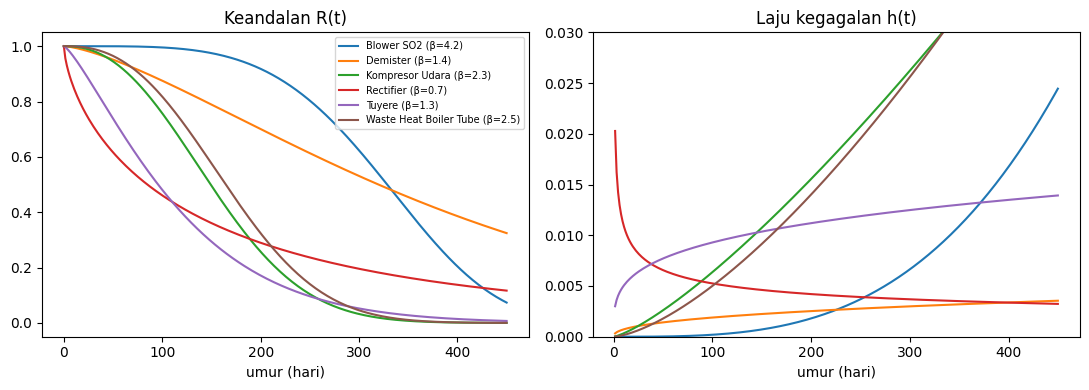

In [ ]:
W["B10_hari"] = W.scale_eta * (-np.log(0.9)) ** (1 / W["shape"])
W["R_90hari_%"] = np.exp(-(90 / W.scale_eta) ** W["shape"]) * 100
from math import gamma
W["MTTF_hari"] = W.scale_eta * np.array([gamma(1 + 1 / sh) for sh in W["shape"]])   # rata-rata umur = eta * Gamma(1+1/beta)
print(W[["shape", "scale_eta", "B10_hari", "MTTF_hari", "R_90hari_%"]].round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 4)); tt = np.linspace(0, 450, 300)
for jenis, r in W.iterrows():
    ax[0].plot(tt, np.exp(-(tt / r.scale_eta) ** r["shape"]), label=f"{jenis} (β={r['shape']:.1f})")
    ax[1].plot(tt[1:], (r["shape"]/r.scale_eta) * (tt[1:]/r.scale_eta) ** (r["shape"]-1), label=jenis)
ax[0].set_title("Keandalan R(t)"); ax[0].set_xlabel("umur (hari)"); ax[0].legend(fontsize=7)
ax[1].set_title("Laju kegagalan h(t)"); ax[1].set_xlabel("umur (hari)"); ax[1].set_ylim(0, .03)
plt.tight_layout(); plt.show()

**Kesimpulan modul 4.**
*   58 kejadian tak terjadwal, MTBF pabrik 110 jam, MTTR 3,1 jam. Oxygen Plant dan FSF paling sering gagal (MTBF sekitar 592 jam).
*   Tidak ada tren perburukan (Laplace p = 0,484; β = 1,10).
*   Weibull: Blower SO2 β = 4,2 (aus kuat), kompresor 2,3, boiler tube 2,5, tuyere 1,3 (hampir acak), rectifier 0,7 (gagal dini). CI lebar karena sampel kecil.




